# 03 — Filtro de Kalman 1: pesos dinámicos β̂_t

**Dueño:** Juan Manuel Espinosa (JME) · **Revisor:** Gonzalo Cano (GC) · **Guía:** `docs/instrucciones/03_kalman_pesos.md`

**Objetivo.** Rastrear en tiempo real el vector cointegrante del grupo GLD-GDX-AEM-FNV y producir, día por día, el
**término de corrección de error** (ECT) que normaliza el filtro 2.

> Este notebook solo **muestra**: la lógica vive en `kalman/weights_filter.py` y las figuras en
> `performance/figures.py`; `python main.py` corre lo mismo y escribe `artifacts/kf1_weights.parquet`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.diagnostic import acorr_ljungbox

from data.split import load_split_dates, slice_split
from kalman.weights_filter import (ABSORPTION_TOLERANCE, BURN_IN, TRADE_HALF_LIVES, WeightsFilter, absorbed_fraction,
                                   calibrate_q, ect_comparison, run_weights_filter, static_ect)
from main import ARTIFACTS, FIGURES

pd.set_option("display.width", 160)
summary = json.loads((ARTIFACTS / "johansen_summary.json").read_text())
params = json.loads((ARTIFACTS / "params.json").read_text())["kf1"]
kf1 = pd.read_parquet(ARTIFACTS / "kf1_weights.parquet")
prices = pd.read_parquet(ARTIFACTS / "prices.parquet")
dates = load_split_dates(ARTIFACTS / "split_dates.json")
tickers, anchor = summary["tickers"], summary["anchor"]
print(f"Grupo: {'-'.join(tickers)}; pata ancla: {anchor}; {len(kf1)} días")

Grupo: GLD-GDX-AEM-FNV; pata ancla: GLD; 3729 días


## 1. Formulación de espacio de estados (sesiones 13 y 14)

Con P_t = **log-precios** (como en Johansen) y la pata ancla GLD con peso fijo +1:

$$\text{Estado: } z_t = z_{t-1} + w_t,\quad w_t\sim\mathcal N(0,Q),\qquad z_t = (c_t,\ \beta_t^{GDX},\ \beta_t^{AEM},\ \beta_t^{FNV})^\top$$

$$\text{Observación: } \underbrace{P_t^{GLD}}_{y_t} = \underbrace{\big(1,\ -P_t^{GDX},\ -P_t^{AEM},\ -P_t^{FNV}\big)}_{C_t}\, z_t + v_t,\quad v_t\sim\mathcal N(0,R)$$

- **Normalización y signo.** El peso de GLD vale +1 por construcción (no es parte del estado), así que β y k·β
  ya no son el mismo estado: está identificado. Es la misma convención de Johansen (β̃_GLD = +1), por eso el
  filtro arranca con el β̃ de entrenamiento sin reescalar.
- **ECT.** Con esta forma, ECT_t = β_tᵀP_t − c_t = y_t − C_t z_t. Usamos los pesos **prior**:
  ECT_t = y_t − C_t ẑ_{t|t−1} = ỹ_t, la innovación del filtro (decisión en `docs/decisiones.md`). Es causal y no
  está encogido: el residual posterior es (R/S_t)·ỹ_t, ya absorbió parte de la desviación del día.
- **Ciclo:** `predict()` (P_{t|t−1} = P_{t−1|t−1} + Q) y `update(obs)` (ỹ_t, S_t, K_t, ẑ_{t|t}, P_{t|t}) están
  separados en la clase `WeightsFilter`.

## 2. Inicialización con Johansen (solo entrenamiento)

In [2]:
init = pd.DataFrame({"β̃ Johansen (train)": summary["beta_normalized"]})
print(f"c (media del spread en train) = {summary['intercept_c']:.4f};  vida media del spread en train = "
      f"{summary['half_life_days']:.1f} días")
print(f"P_0 = {params['P0']}, burn-in = {params['burn_in_days']} días (todo dentro de 2012, antes de operar)")
init

c (media del spread en train) = 2.9877;  vida media del spread en train = 25.3 días
P_0 = 252 · Q, burn-in = 252 días (todo dentro de 2012, antes de operar)


,β̃ Johansen (train)
GLD,1.000000
GDX,-0.568595
AEM,0.400419
FNV,-0.370935


## 3. Calibración de Q y R (solo entrenamiento)

- **R** = varianza de los residuales de Johansen en entrenamiento (el ruido de observación es lo que el vector
  estático no explica).
- **Q = q · I** (forma δ/(1−δ)·I de clase; solo importa q/R).
- **q por separación de escalas de tiempo.** Cada día el filtro mueve su ajuste en C_t K_t · ỹ_t, con
  C_t K_t = 1 − R/S_t: es la fracción de cada sorpresa que *absorbe* moviendo pesos en vez de esperar a que los
  precios la corrijan. En una operación típica de 2 vidas medias (≈ 50 días) se absorbe 1 − (1 − w̄)^50. Elegimos
  el **mayor q que absorbe a lo más 20 %**: el filtro puede seguir una deriva lenta, pero no se come la reversión
  que se quiere operar.

**Por qué no máxima verosimilitud:** la verosimilitud premia innovaciones de ruido blanco y eso se logra
persiguiendo el spread (con R fija, la verosimilitud de train es máxima cerca de q ≈ 10⁻⁶ y ahí la vida media del ECT es de 3–4 días). El ECT revertiría *por construcción*
—lo regresaría el filtro, no los precios— y no habría nada que operar. Es la trampa de la guía 03.

In [3]:
print(json.dumps({k: params[k] for k in ["q", "R", "q_over_R", "absorption_median_train", "absorbed_in_trade_train"]}, indent=2))

{
  "q": 9.2310924e-10,
  "R": 0.0019210468,
  "q_over_R": 4.8052409e-07,
  "absorption_median_train": 0.0043940814,
  "absorbed_in_trade_train": 0.2
}


**Sensibilidad del criterio (solo entrenamiento).** Cómo cambia q al mover la tolerancia de absorción, y qué
le pasa al ECT dinámico en train (la tolerancia de 20 % quedó fijada antes de ver prueba y validación).

In [4]:
train = slice_split(np.log(prices[tickers]), dates, "train")
beta0 = np.array([summary["beta_normalized"][t] for t in tickers])
sensitivity = []
for tolerance in (0.10, ABSORPTION_TOLERANCE, 0.40):
    q = calibrate_q(train, anchor, beta0, summary["intercept_c"], params["R"], summary["half_life_days"], tolerance)
    out = run_weights_filter(train, anchor, beta0, summary["intercept_c"], q, params["R"]).iloc[BURN_IN:]
    comparison = ect_comparison(out.assign(split="train", ect_static=static_ect(train, beta0, summary["intercept_c"])))
    dynamic = comparison.set_index("ect").loc["dynamic"]
    sensitivity.append({"tolerancia": tolerance, "q": q, "memoria ≈ 1/w̄ (días)": 1 / out["absorption"].median(),
                        "ECT dinámico: vida media (train)": dynamic["half_life"], "ADF p (train)": dynamic["adf_pvalue"]})
pd.DataFrame(sensitivity).style.format({"q": "{:.2e}", "memoria ≈ 1/w̄ (días)": "{:.0f}", "ECT dinámico: vida media (train)": "{:.1f}", "ADF p (train)": "{:.4f}"})

,tolerancia,q,memoria ≈ 1/w̄ (días),ECT dinámico: vida media (train),ADF p (train)
0,0.100000,2.08e-10,481,23.0,0.0001
1,0.200000,9.23e-10,228,21.2,0.0001
2,0.400000,4.86e-09,100,17.2,0.0000


## 4. Verificación: el filtro reproduce el ejemplo trabajado de clase

Ejemplo 1 de la sesión 13 (y_t = β_t x_t, β̂₀ = 1, P₀ = 0.5, Q = 0.01, R = 0.25). En nuestra forma
y_t = c_t − β'_t x_t basta fijar c = 0 sin varianza y β' = −β: β̂ y P coinciden con la tabla de clase y K cambia de
signo. Es la misma prueba que `tests/test_kalman_weights.py`.

In [5]:
kf = WeightsFilter(state=np.array([0.0, -1.0]), P_cov=np.diag([0.0, 0.5]), Q=np.diag([0.0, 0.01]), R=0.25, anchor=0)
rows = []
for t, (x, y) in enumerate([(1.0, 1.30), (1.2, 1.40), (0.9, 1.20), (1.1, 1.25)], start=1):
    _, P_prior = kf.predict()
    step = kf.update(np.array([y, x]))
    rows.append({"t": t, "x_t": x, "y_t": y, "P⁻": P_prior[1, 1], "ỹ": step["innov"], "S": step["innov_var"],
                 "K": -step["gain"][1], "β̂_t": -step["state_post"][1], "P_t": step["P_post"][1, 1]})
pd.DataFrame(rows).set_index("t").round(3)

,x_t,y_t,P⁻,ỹ,S,K,β̂_t,P_t
t,,,,,,,,
1,1.0,1.30,0.510,0.300,0.760,0.671,1.201,0.168
2,1.2,1.40,0.178,-0.042,0.506,0.422,1.184,0.088
3,0.9,1.20,0.098,0.135,0.329,0.267,1.220,0.074
4,1.1,1.25,0.084,-0.092,0.352,0.263,1.196,0.060


## 5. Ejemplo numérico con los datos del proyecto (5 días)

Los primeros días después del burn-in. Prior → innovación (= ECT dinámico) → S_t → ganancia → posterior. La
ganancia es pequeña (q/R ≈ 5 × 10⁻⁷): cada día el filtro corrige los pesos en el orden de 10⁻⁵.

In [6]:
days = kf1.index[BURN_IN:BURN_IN + 5]
example = kf1.loc[days, ["beta_prior_GDX", "intercept_prior", "ect_dynamic", "innov_var", "gain_GDX", "absorption",
                         "beta_GDX", "intercept"]]
example.columns = ["β GDX prior", "c prior", "ỹ_t = ECT", "S_t", "K_t[GDX]", "C_t K_t", "β GDX posterior", "c posterior"]
example.style.format("{:.6f}")

,β GDX prior,c prior,ỹ_t = ECT,S_t,K_t[GDX],C_t K_t,β GDX posterior,c posterior
date,,,,,,,,
2013-01-04 00:00:00,-0.568962,2.987849,0.027263,0.001930,-0.000384,0.004672,-0.568973,2.987852
2013-01-07 00:00:00,-0.568973,2.987852,0.023302,0.001930,-0.000382,0.004626,-0.568982,2.987854
2013-01-08 00:00:00,-0.568982,2.987854,0.026753,0.001930,-0.000382,0.004640,-0.568992,2.987857
2013-01-09 00:00:00,-0.568992,2.987857,0.030702,0.001930,-0.000381,0.004633,-0.569003,2.987861
2013-01-10 00:00:00,-0.569003,2.987861,0.033453,0.001930,-0.000385,0.004661,-0.569016,2.987864


## 6. Figura 3 — pesos dinámicos y figura 5 — ganancia de Kalman

Las genera `main.py`. En entrenamiento y prueba los pesos casi no se mueven; en validación (2024–2026, rally del oro
con las mineras subiendo más que el metal) el filtro mueve GDX de −0.57 a −0.60 y AEM de 0.40 a 0.35. La ganancia
(C_t K_t) sube en validación porque las sorpresas son más grandes.

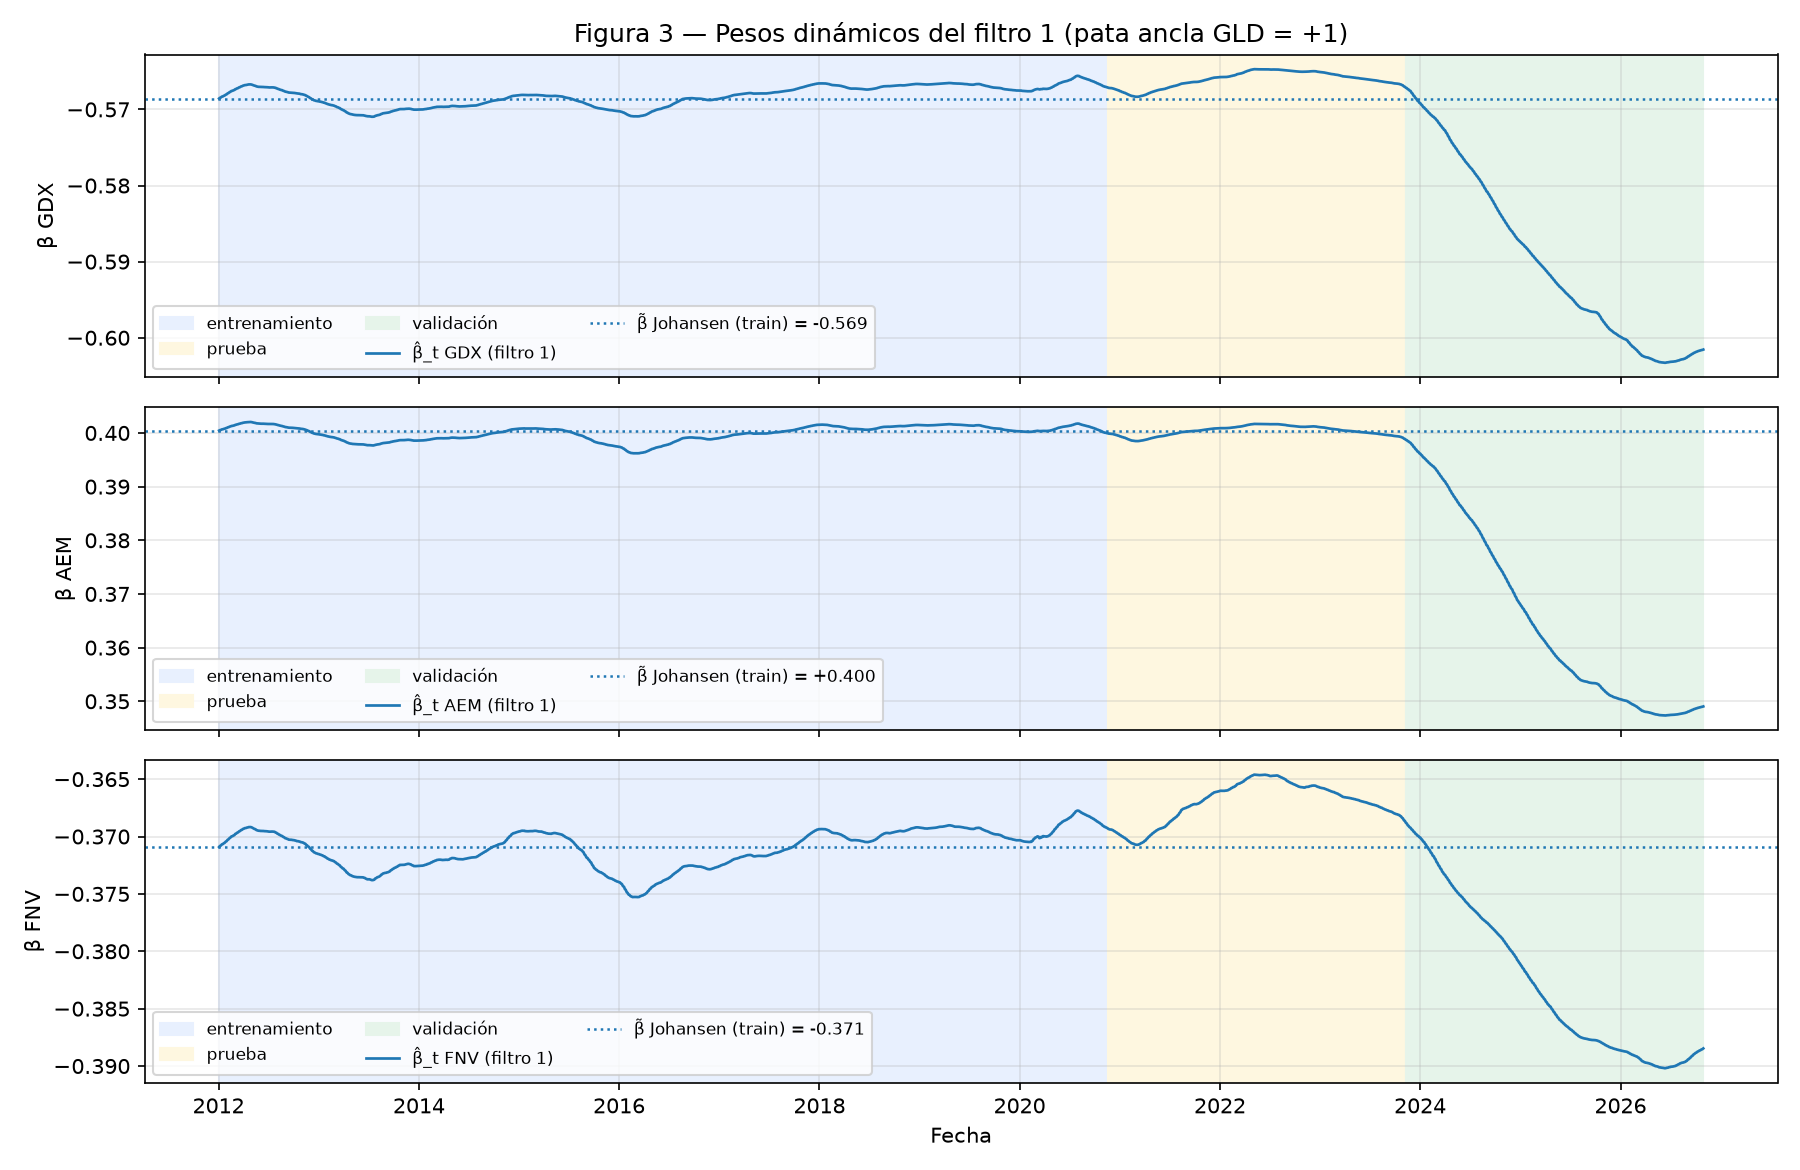

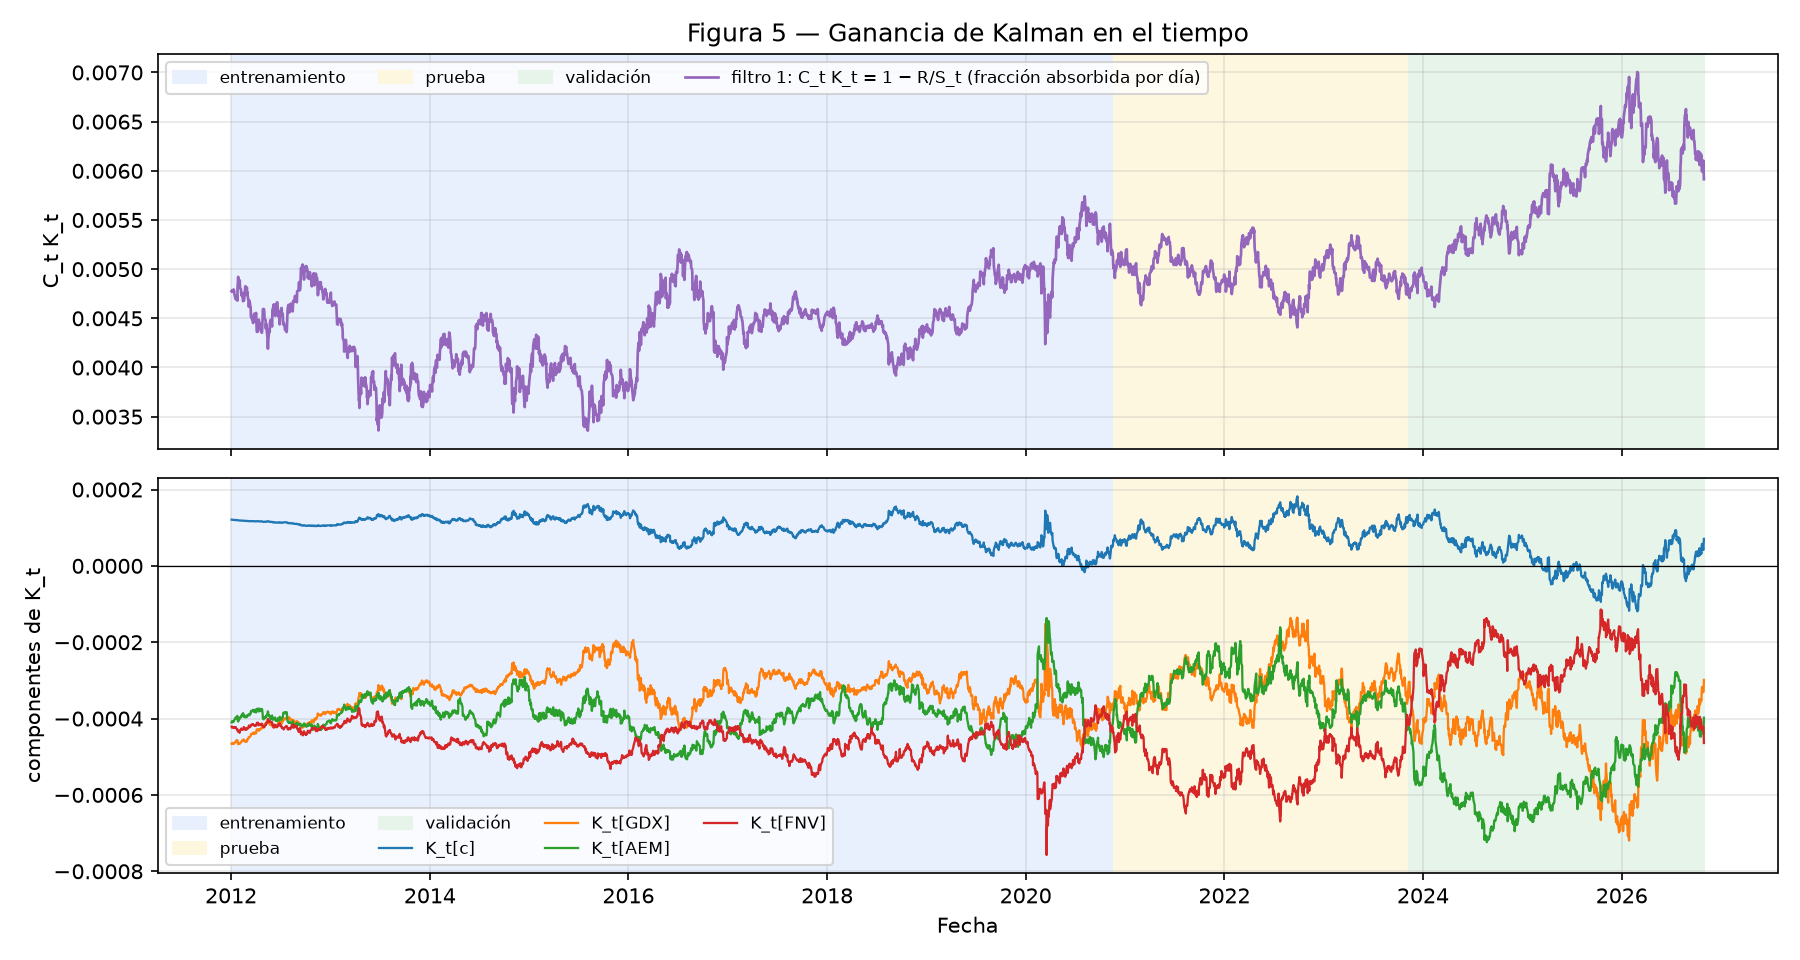

In [7]:
display(Image(filename=str(FIGURES / "fig03_pesos_dinamicos.png")))
display(Image(filename=str(FIGURES / "fig05_ganancia_kalman.png")))

## 7. ECT estático vs dinámico (sugerencia del profesor)

El estático usa el β̃ y la c de Johansen congelados en train; el dinámico es la innovación del filtro 1.

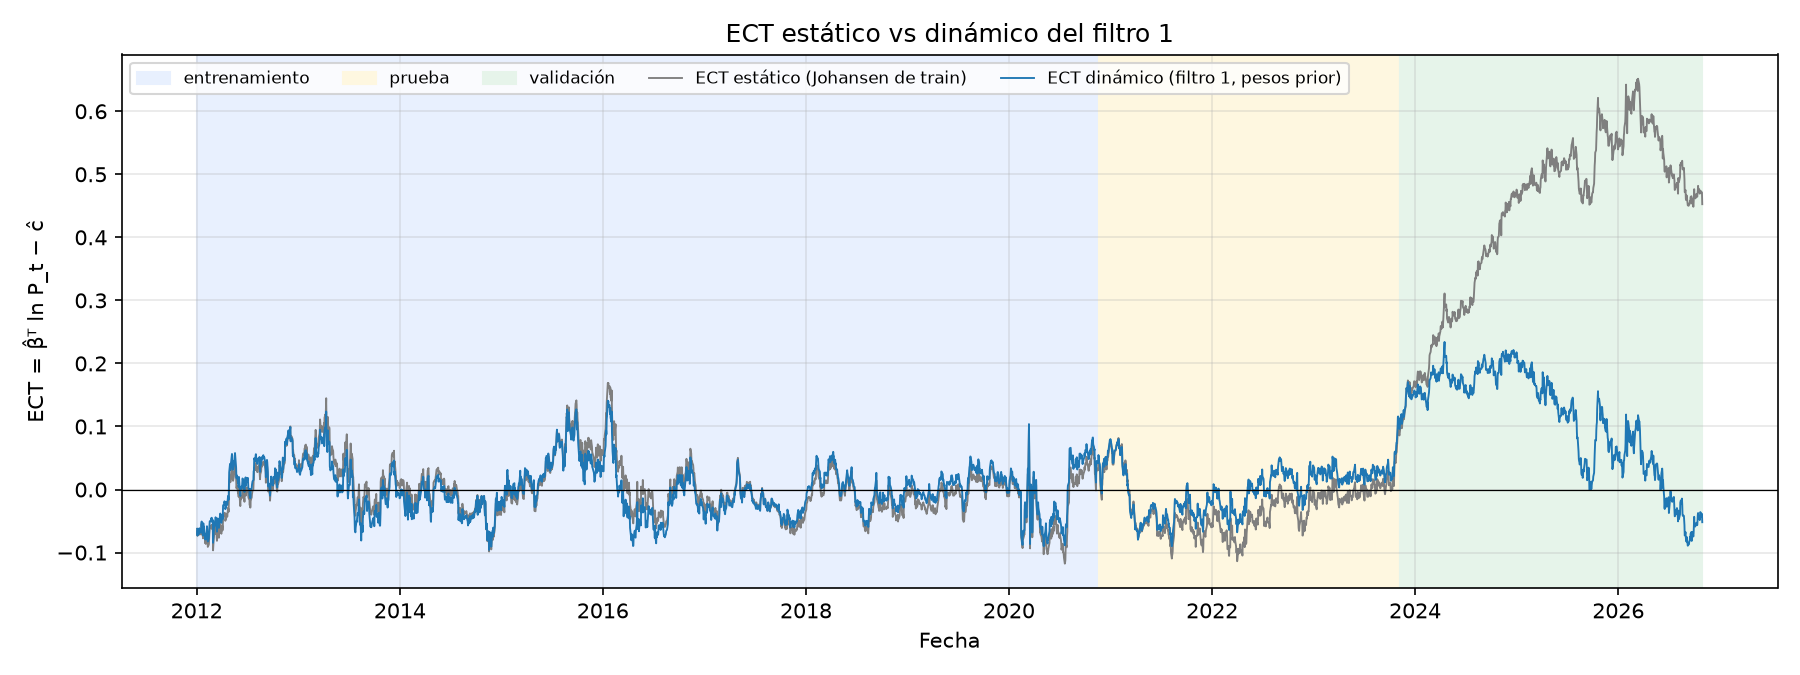

,ect,split,mean,std,adf_stat,adf_pvalue,half_life
0,static,train,0.0005,0.0433,-4.4319,0.0003,24.5069
1,static,test,-0.0265,0.0411,-2.0779,0.2535,46.2609
2,static,validation,0.4351,0.1348,-2.3458,0.1576,111.9782
3,dynamic,train,-0.0012,0.0403,-4.7659,0.0001,21.1845
4,dynamic,test,0.0006,0.0376,-2.3921,0.1440,37.0081
5,dynamic,validation,0.1097,0.0821,-0.8559,0.8021,200.3307


In [8]:
display(Image(filename=str(FIGURES / "ect_estatico_vs_dinamico.png")))
ect_comparison(kf1).round(4)

**Lectura.**
- **Prueba:** el estático queda desplazado (media −0.027) y el dinámico vuelve a oscilar alrededor de cero; ninguno
  rechaza raíz unitaria con ADF en 3 años, pero el dinámico tiene vida media menor.
- **Validación:** el estático se va a +0.44 (≈ 10 desviaciones estándar de train) y no regresa. El dinámico también
  se abre (+0.2 durante 2024–2025) pero regresa a cero hacia 2026. La relación de train **no** se sostiene en
  validación; el filtro reduce el daño pero no lo elimina. Para la estrategia esto significa stops y holding máximo
  (parte 05) y una discusión honesta en el reporte.

## 8. Diagnóstico de las innovaciones

En el filtro 1 la innovación **es** el ECT, y queremos que revierta a la media con una vida media de semanas: por eso
**no** debe ser ruido blanco (si lo fuera, no habría nada que operar). La prueba de innovaciones blancas con
varianza ≈ 1 (prueba 4) aplica al filtro 2. Aquí revisamos la escala: en validación la varianza normalizada ≫ 1
indica que el filtro está sobreconfiado ahí (las sorpresas son mayores que lo que R y Q de train esperan).

In [9]:
diagnostics = kf1.loc[~kf1["burn_in"]].groupby("split", sort=False)["innov_norm"].agg(
    media="mean", varianza="var",
    ljung_box_p=lambda s: acorr_ljungbox(s, lags=[10])["lb_pvalue"].iloc[0])
diagnostics.round(4)

,media,varianza,ljung_box_p
split,,,
train,-0.0276,0.8398,0.0
test,0.0126,0.7321,0.0
validation,2.4957,3.4869,0.0


## 9. Formulación Powell del filtro 1

Texto completo en `docs/powell.md` (sección filtro 1).

| Elemento | Filtro 1 | En el código |
|---|---|---|
| Estado S_t | información I_t = log-precios P_t; creencia B_t = (ẑ_t, P_t^cov) con ẑ = (c, β_GDX, β_AEM, β_FNV) | `WeightsFilter.state`, `.P_cov` |
| Decisión x_t | la corrección K_t ỹ_t aplicada a los pesos | `update()` |
| Información exógena W_{t+1} | log-precios del día siguiente | fila de `log_prices` |
| Transición S^M | predecir (A = I, P + Q) y actualizar (ỹ, S, K, ẑ, P) | `predict()`, `update()` |
| Objetivo | min E[ỹ_t²] sujeto a que la deriva de β sea lenta frente a la reversión (≤ 20 % absorbido por operación) | `calibrate_q` |
| Política | PFA con θ = (Q, R): la ganancia de Kalman es la regla; θ se calibra en train | `make_noise_matrices` |

## 10. Qué recibe el filtro 2 (GC)

`artifacts/kf1_weights.parquet`, columna **`ect_dynamic`** (ECT con pesos prior, causal) y **`burn_in`** (no operar
esos días). También: `ect_static` para la comparación de la parte 05, `beta_<ticker>` (pesos posteriores
β̂_{t|t}, disponibles al cierre de t, para el sizing), `beta_prior_<ticker>`, `gain_*`, `var_post_*`,
`absorption` y `split`. Los parámetros están en `artifacts/params.json` → `kf1`.

## Resumen de resultados (parte 03)

| Resultado | Valor |
|---|---|
| Estado | z_t = (c_t, β_GDX, β_AEM, β_FNV); GLD fijo en +1 |
| Inicialización | β̃ de Johansen en train (+1, −0.569, +0.400, −0.371), c = 2.988; P₀ = 252·Q |
| R | 1.92 × 10⁻³ (varianza de los residuales de Johansen en train) |
| Q | q·I con q = 9.2 × 10⁻¹⁰ (q/R ≈ 4.8 × 10⁻⁷): absorbe 20 % de una desviación en 2 vidas medias |
| Burn-in | 252 días (2012) |
| ECT dinámico | innovación con pesos prior; media ≈ 0 en prueba, +0.11 en validación (estático: +0.44) |
| Pesos al final | GDX −0.602, AEM +0.349, FNV −0.388 (se movieron sobre todo en validación) |
| Pruebas | `test_normalization` (5 casos) y `test_kalman_weights` (ejemplo de clase reproducido) en verde |

- **Hallazgo:** la relación de train no se sostiene en validación; el filtro 1 reduce el desplazamiento del ECT
  pero no lo elimina. Limitación central para el reporte.
- **Decisión clave a defender:** q por separación de escalas, no por máxima verosimilitud (la verosimilitud
  convierte el ECT en ruido blanco y la estrategia se queda sin señal).